# Project 9: Optimizer Comparison Using a Neural Network

**Objective:** Build a neural network using the Iris dataset, train it using SGD and Adam optimizers, and compare training behavior and classification performance.

## Task 1: Build a Simple Neural Network Using the Iris Dataset

**Aim:** Load the Iris dataset, split it into training and testing sets, standardize the features, and build a neural network for flower classification.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import SGD, Adam
from tensorflow.keras.utils import to_categorical

In [2]:
# Load the Iris dataset
iris = load_iris()
X = iris.data
y = iris.target

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize the features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert target labels to categorical format
y_train_cat = to_categorical(y_train, num_classes=3)
y_test_cat = to_categorical(y_test, num_classes=3)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])
print("Flower classes:", iris.target_names)

Training samples: 120
Testing samples: 30
Number of features: 4
Flower classes: ['setosa' 'versicolor' 'virginica']


In [3]:
# Build a simple neural network
def create_model():
    model = Sequential([
        Input(shape=(4,)),
        Dense(10, activation="relu"),
        Dense(8, activation="relu"),
        Dense(3, activation="softmax")
    ])
    return model

model = create_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │            88 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 165 (660.00 B)

 Trainable params: 165 (660.00 B)

 Non-trainable params: 0 (0.00 B)

**Explanation:**
- The Iris dataset contains 150 flower samples from three species.
- The data is divided into 80% training data and 20% testing data.
- StandardScaler standardizes the input features.
- The neural network has two hidden layers and an output layer with three neurons.

**Result:** A simple neural network was created for Iris flower classification.

---

## Task 2: Train the Model Using SGD and Adam Optimizers

**Aim:** Train the neural network using SGD and Adam, then compare their training loss and accuracy.

In [4]:
# Set up both optimizers
optimizer_settings = {
    "SGD": lambda: SGD(learning_rate=0.01),
    "Adam": lambda: Adam(learning_rate=0.01)
}

training_results = {}
trained_models = {}

# Train a separate model for each optimizer
for name, optimizer_factory in optimizer_settings.items():
    model = create_model()

    model.compile(
        optimizer=optimizer_factory(),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    history = model.fit(
        X_train,
        y_train_cat,
        epochs=50,
        batch_size=8,
        verbose=0
    )

    training_results[name] = history.history
    trained_models[name] = model

    print(f"{name} training completed")
    print(f"Final training accuracy: {history.history['accuracy'][-1] * 100:.2f}%")
    print(f"Final training loss: {history.history['loss'][-1]:.4f}")
    print()

SGD training completed
Final training accuracy: 95.83%
Final training loss: 0.2145

Adam training completed
Final training accuracy: 99.17%
Final training loss: 0.0372



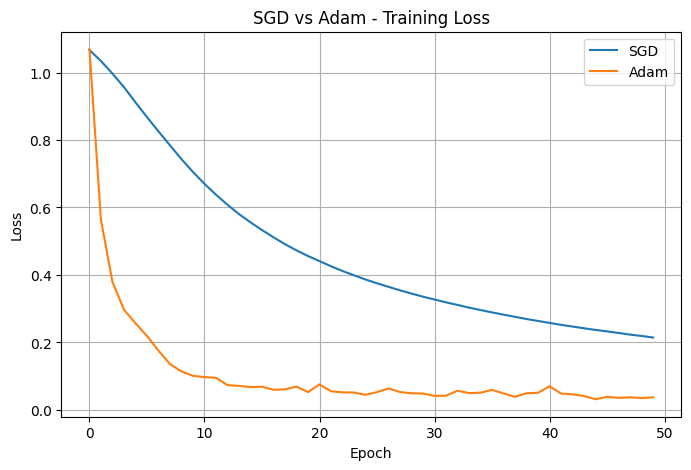

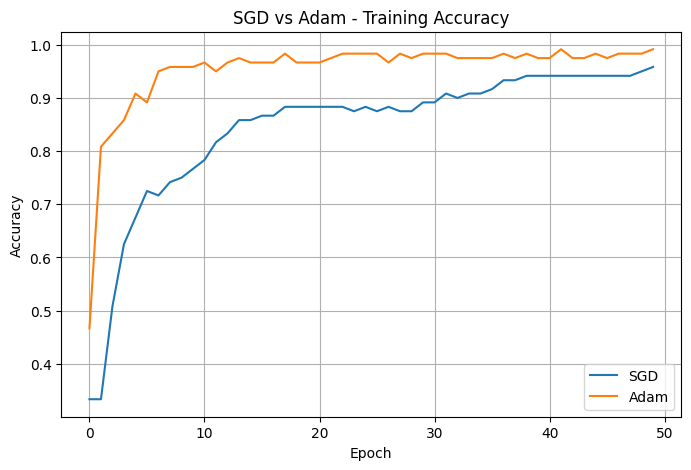

In [5]:
# Plot training loss
plt.figure(figsize=(8, 5))

for name, history in training_results.items():
    plt.plot(history["loss"], label=name)

plt.title("SGD vs Adam - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# Plot training accuracy
plt.figure(figsize=(8, 5))

for name, history in training_results.items():
    plt.plot(history["accuracy"], label=name)

plt.title("SGD vs Adam - Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

**Explanation:**
- SGD updates weights using gradients to reduce the loss.
- Adam adapts the learning rate for each model parameter.
- Both models are trained for 50 epochs.
- The graphs show how loss and accuracy change during training.

**Result:** The models were trained using both optimizers, and their training loss and accuracy were plotted.

---

## Task 3: Compare Training Results and Classification Performance

**Aim:** Evaluate both trained models on the test data and compare their accuracy, loss, precision, recall, and F1-score.

In [6]:
# Evaluate both trained models on the same test set
comparison = {}

for name, model in trained_models.items():
    test_loss, test_accuracy = model.evaluate(
        X_test, y_test_cat, verbose=0
    )

    probabilities = model.predict(X_test, verbose=0)
    y_pred = np.argmax(probabilities, axis=1)

    comparison[name] = {
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
        "predictions": y_pred
    }

    print(f"Optimizer: {name}")
    print(f"Test loss: {test_loss:.4f}")
    print(f"Test accuracy: {test_accuracy * 100:.2f}%")
    print("\nClassification report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names,
        zero_division=0
    ))
    print("-" * 50)

Optimizer: SGD
Test loss: 0.2757
Test accuracy: 86.67%

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.88      0.70      0.78        10
   virginica       0.75      0.90      0.82        10

    accuracy                           0.87        30
   macro avg       0.88      0.87      0.87        30
weighted avg       0.88      0.87      0.87        30

--------------------------------------------------
Optimizer: Adam
Test loss: 0.1107
Test accuracy: 96.67%

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30

----------------------------

In [7]:
# Display a simple comparison table
print(f"{'Optimizer':<12}{'Test Loss':<15}{'Test Accuracy':<15}")

for name, result in comparison.items():
    print(
        f"{name:<12}"
        f"{result['test_loss']:<15.4f}"
        f"{result['test_accuracy'] * 100:.2f}%"
    )

best_optimizer = max(
    comparison,
    key=lambda name: comparison[name]["test_accuracy"]
)
print(f"\nHigher test accuracy in this run: {best_optimizer}")

Optimizer   Test Loss      Test Accuracy  
SGD         0.2757         86.67%
Adam        0.1107         96.67%

Higher test accuracy in this run: Adam


**Explanation:**
- Test loss measures prediction error on unseen samples.
- Test accuracy measures the percentage of correctly classified flowers.
- Precision, recall, and F1-score summarize classification performance for each species.
- Results can vary slightly because neural network training includes random initialization.

**Result:** SGD and Adam were evaluated and compared using test loss, test accuracy, and classification reports.

## Overall Conclusion

A neural network was built using the Iris dataset and trained with SGD and Adam optimizers. Their performance was compared using training graphs and test classification metrics. Adam often converges faster, but the actual test results determine which optimizer performed better in this run.